# GH-III model

After trying `test-0-x`, now, we proceed to propose canonical toy models for the paper and test basic properties, preparing for scanning.

`test-3-x` are for the GH-III model, which is more like `Attention`.

In this model, the input $x\in \mathbb{R}^{d\times m}$. We have a key matrix $K \in \mathbb{R}^{m\times m}$, a query matrix $Q \in \mathbb{R}^{m \times m}$, and a value tensor $V \in \mathbb{R}^{m \times m}$. The output of the gate is computed as:
$$
h =  (\mathrm{Softmax}(x^TK^TQx)Vx)_{-1} \in \mathbb{R}^m.
$$
We call this part G-III, gate model type III. We only calculate the last "token" for simplicity and efficiency.
After the gate, we project the hidden state out with a head $W \in \mathbb{R}^{n\times m}$, and the final logits is:
$$
y = Wh \in \mathbb{R}^n.
$$

Visually, one can see
<img src="GHmodels.jpeg" alt="GHmodels" width="600">

We want the toy model to have the following properties:
- 1/3 scaling for gate part
- 3/4 situations of GH can show the 1/3 scaling, 1/4 situation means both high temperature.
- Maybe increasing Hessian, not necessary.

## G-III model

`test-3-2` is for testing G-III. We train with attention logits. But use SGD now!

In [1]:
import torch
import torch.nn.functional as F
import torch.nn as nn
from dataclasses import dataclass
import matplotlib.pyplot as plt

In [2]:
from scipy.sparse.linalg import LinearOperator, eigsh
import numpy as np

def prepare_hvp(loss, params):
    grads = torch.autograd.grad(loss, params, create_graph=True)
    flat_grad = torch.cat([g.reshape(-1) for g in grads])

    def hvp(vec):
        grad_vec = (flat_grad * vec).sum()
        hv = torch.autograd.grad(grad_vec, params, retain_graph=True)
        return torch.cat([h.reshape(-1) for h in hv])

    return hvp

def lanczos(matrix_vector, dim: int, neigs: int):
    """ Invoke the Lanczos algorithm to compute the leading eigenvalues and eigenvectors of a matrix / linear operator
    (which we can access via matrix-vector products). """

    def mv(vec: np.ndarray):
        return matrix_vector(torch.tensor(vec))

    operator = LinearOperator((dim, dim), matvec=mv)
    evals, evecs = eigsh(operator, neigs)
    return torch.from_numpy(np.ascontiguousarray(evals[::-1]).copy()).float(), \
           torch.from_numpy(np.ascontiguousarray(np.flip(evecs, -1)).copy()).float()

def get_hessian_eigenvalues(network, losses, neigs=1, return_trace=False, nprobe=16):
    params = [p for p in network.parameters() if p.requires_grad]
    hvps = [prepare_hvp(loss, params) for loss in losses] # list of hvp functions
    def hvp_delta(vec):
        result = torch.zeros_like(vec)
        for hvp in hvps:
            result += hvp(vec)
        return result / len(hvps)
    nparams = torch.cat([p.reshape(-1) for p in params]).numel()
    evals, _ = lanczos(hvp_delta, nparams, neigs=neigs)
    if return_trace:
        trace = 0.0
        for _ in range(nprobe):
            v = torch.randn(nparams)
            hv = hvp_delta(v)
            trace += torch.dot(v, hv).item()
        trace /= nprobe
        return evals, trace
    else:
        return evals

In [3]:
# ---- Config ----
@dataclass
class Config:
    vocab_size: int = 128     # vocab size (n)
    n_embd: int = 32         # model width (m)
    beta: float = 1.0              # scaling factor for the logits
    beta_g: float = 1.0            # scaling factor for the gating
    teacher: bool = False             # whether to use teacher model
    d_ctx: int = 8             # context length (d_ctx)

# ---- Utils ----
def rmsnorm(x: torch.Tensor):
    return F.rms_norm(x, (x.size(-1),))

# ---- Model ----
class GATE_III(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.qkv = nn.Parameter(torch.randn(3 * cfg.n_embd, cfg.n_embd) / (cfg.n_embd ** 0.5))
        
    def forward(self, x: torch.Tensor):
        # x: (B, d_ctx, n_embd)
        # Q: (n_embd, n_embd)
        # K: (n_embd, n_embd)
        # V: (n_embd, n_embd)
        # h: (n_embd,)
        qkv = F.linear(x, self.qkv)  # (B, d_ctx, 3 * n_embd)
        q, k, v = qkv.chunk(3, dim=-1)  # each: (B, d_ctx, n_embd)
        attn_logits = (q[:,-1].unsqueeze(1) @ k.transpose(-2, -1)) * self.cfg.beta_g / (self.cfg.n_embd ** 0.5) # (B, 1, n_embd) @ (B, n_embd, d_ctx) -> (B, 1, d_ctx)
        attn = F.softmax(attn_logits, dim=-1) 
        out = attn @ v  # (B, 1, d_ctx) @ (B, d_ctx, n_embd) -> (B, 1, n_embd)
        return out.squeeze(1), attn_logits.squeeze(1)  # (B, n_embd), (B, d_ctx)

In [29]:
t_cfg = Config(beta = 1.0, beta_g = 500.0, teacher = True)
d_ctx = t_cfg.d_ctx
teacher = GATE_III(t_cfg)
s_cfg = Config()
student = GATE_III(s_cfg)
with torch.no_grad():
        #student.qkv[s_cfg.n_embd * 2:].copy_(teacher.qkv[s_cfg.n_embd * 2:]) # same V, copy from teacher
        student.qkv.copy_(teacher.qkv) # same QKV, copy from teacher
        
batch_size = 256
base_lr = 6e-1

optimizer = torch.optim.SGD(student.parameters(), lr=base_lr)

losses = []
#s_logits_stds = []
#t_logits_stds = []
#entropies = []
#t_entropies = []
s_beta_G = []
K_norm = []
Q_norm = []

neigs = 1
log_interval = 200
num_batch_H = 4

num_steps = 20000 # 18s
eign_vals = torch.zeros((num_steps // log_interval, neigs))
traces = torch.zeros(num_steps // log_interval)
test_losses = torch.zeros(num_steps // log_interval)
log_Hessian = True

for step in range(num_steps):
    x = torch.randn(batch_size, d_ctx, s_cfg.n_embd)
    with torch.no_grad():
        teacher_out, teacher_logits = teacher(x)
        teacher_log_probs = F.log_softmax(teacher_logits, dim=-1)
    student_out, student_logits = student(x)
    student_log_probs = F.log_softmax(student_logits, dim=-1)
    loss = F.kl_div(student_log_probs, teacher_log_probs, reduction='batchmean', log_target=True)
    #loss = F.mse_loss(student_out, teacher_out)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    s_beta_G.append(student_logits.std(-1).mean().item())
    Q_norm.append(student.qkv[:s_cfg.n_embd].norm().item())
    K_norm.append(student.qkv[s_cfg.n_embd:s_cfg.n_embd * 2].norm().item())

    if (step + 1) % log_interval == 0 and log_Hessian:
        Hlosses = []
        for _ in range(num_batch_H):
            x = torch.randn(batch_size, d_ctx, s_cfg.n_embd)
            with torch.no_grad():
                teacher_output, teacher_logits = teacher(x)  # (B, vocab_size)
                teacher_log_probs = F.log_softmax(teacher_logits, dim=-1)
            student_output, student_logits = student(x)  # (B, vocab_size)
            student_log_probs = F.log_softmax(student_logits, dim=-1)
            #Hlosses.append(F.mse_loss(student_output, teacher_output))
            Hlosses.append(F.kl_div(student_log_probs, teacher_log_probs, reduction='batchmean', log_target=True))
        est_evals, trace = get_hessian_eigenvalues(student, Hlosses, neigs=neigs, return_trace=True)
        with torch.no_grad():
            test_losses[(step + 1) // log_interval - 1] = torch.stack(Hlosses).mean().item()
            eign_vals[(step + 1) // log_interval - 1] = est_evals
            traces[(step + 1) // log_interval - 1] = trace
        del Hlosses
        print('step', step +1)

step 200
step 400
step 600
step 800
step 1000
step 1200
step 1400
step 1600
step 1800
step 2000
step 2200
step 2400
step 2600
step 2800
step 3000
step 3200
step 3400
step 3600
step 3800
step 4000
step 4200
step 4400
step 4600
step 4800
step 5000
step 5200
step 5400
step 5600
step 5800
step 6000
step 6200
step 6400
step 6600
step 6800
step 7000
step 7200
step 7400
step 7600
step 7800
step 8000
step 8200
step 8400
step 8600
step 8800
step 9000
step 9200
step 9400
step 9600
step 9800
step 10000
step 10200
step 10400
step 10600
step 10800
step 11000
step 11200
step 11400
step 11600
step 11800
step 12000
step 12200
step 12400
step 12600
step 12800
step 13000
step 13200
step 13400
step 13600
step 13800
step 14000
step 14200
step 14400
step 14600
step 14800
step 15000
step 15200
step 15400
step 15600
step 15800
step 16000
step 16200
step 16400
step 16600
step 16800
step 17000
step 17200
step 17400
step 17600
step 17800
step 18000
step 18200
step 18400
step 18600
step 18800
step 19000
step 192

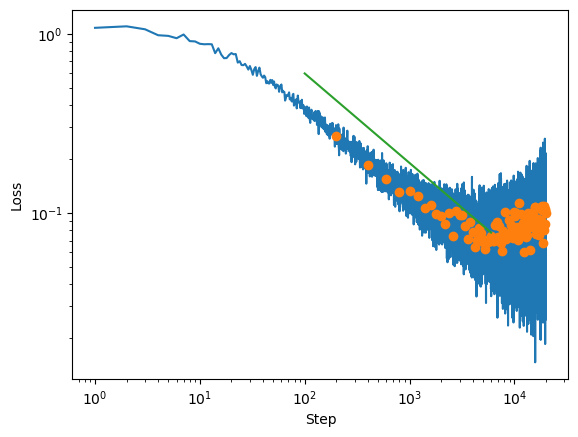

In [30]:
plt.plot(range(1, len(losses) + 1), losses)
if log_Hessian:
    plt.plot(np.arange(1, num_steps // log_interval + 1) * log_interval, test_losses, 'o')
plt.plot([100, 6000], [.6, .6/60**0.5])
plt.xlabel('Step')
plt.ylabel('Loss')
plt.xscale('log')
plt.yscale('log')

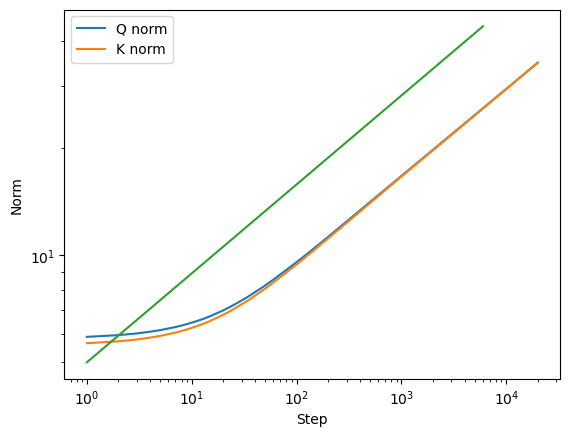

In [31]:
plt.plot(range(1, len(losses) + 1), Q_norm, label='Q norm')
plt.plot(range(1, len(losses) + 1), K_norm, label='K norm')
plt.plot([1,6000], [5, 5 * 6000 ** (1/4)])
plt.xlabel('Step')
plt.ylabel('Norm')
plt.legend()
plt.xscale('log')
plt.yscale('log')

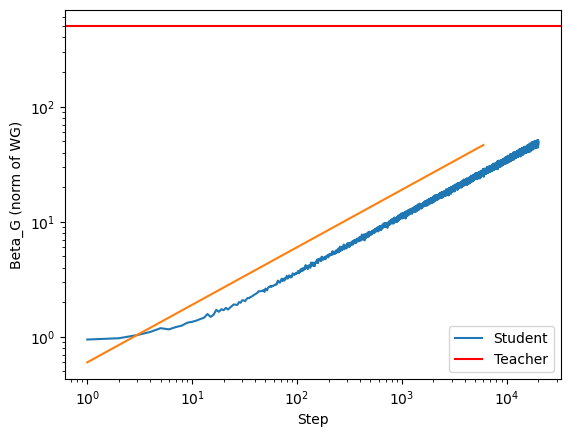

In [32]:
plt.plot(range(1, len(losses) + 1), s_beta_G, label='Student')
plt.axhline(t_cfg.beta_g, label='Teacher', color='red')
plt.plot([1,6000], [.6, .6 * 6000 ** (1/2)])
plt.xlabel('Step')
plt.ylabel('Beta_G (norm of WG)')
plt.xscale('log')
plt.yscale('log')
plt.legend()

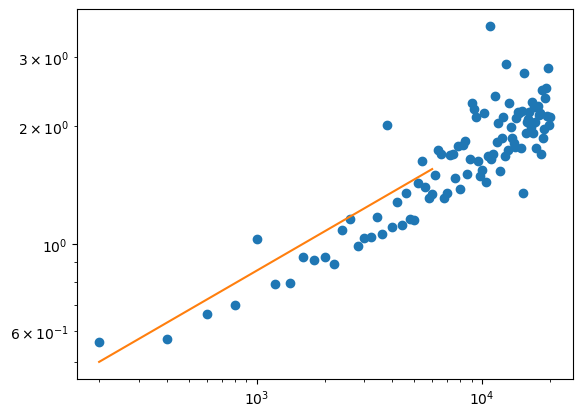

In [33]:
if log_Hessian:
    plt.plot(np.arange(1, num_steps // log_interval + 1) * log_interval, eign_vals.numpy(), 'o')
    plt.plot([200, 6000], [5e-1, 5e-1 * 30 ** (1/3)])
    plt.xscale('log')
    plt.yscale('log')

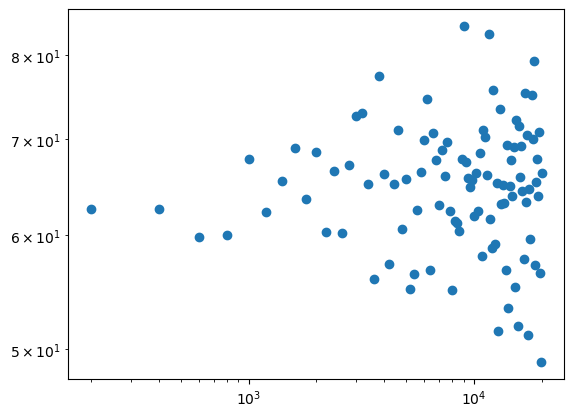

In [34]:
if log_Hessian:
    plt.plot(np.arange(1, num_steps // log_interval + 1) * log_interval, traces.numpy(), 'o')
    plt.xscale('log')
    plt.yscale('log')

The trace seems to be concerved.

Edge of stability makes the alignment impossible? Such that the logits follow gradient flow, not the Q and K norms?

Try to write down the theory!

Then think about figure plan, what more experiments to do (necessary ones first).